In [9]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (11, 3.4)

# Part A Step 1: Load the data and read the header

In [10]:
url = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"
raw = pd.read_csv(url, comment="#")
raw.tail()

,year,month,decimal date,average,deseasonalized,ndays,sdev,unc
818,2026,5,2026.3750,432.34,429.05,19,0.64,0.28
819,2026,6,2026.4583,431.43,429.00,19,0.27,0.12
820,2026,7,2026.5417,429.13,428.74,21,0.61,0.26
821,2026,8,2026.6250,427.55,429.48,17,0.38,0.18
822,2026,9,2026.7083,426.07,429.55,18,0.51,0.23


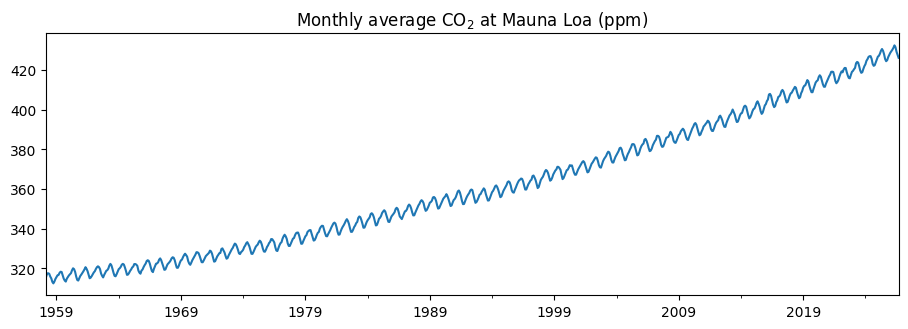

In [11]:
raw.index = pd.to_datetime(raw[["year", "month"]].assign(day=1))
data = raw.asfreq("MS")
co2 = data["average"]
co2.plot(title="Monthly average CO$_2$ at Mauna Loa (ppm)")
plt.show()

In [13]:
train = co2.loc["1975-01":"2025-12"]
test = co2["2026-01":"2026-09"]
print(len(train), "training months,", len(test), "test months")
raw.loc["1975":"2025"].query("sdev < 0")[["average","ndays","sdev"]]

612 training months, 9 test months


,average,ndays,sdev
1975-12-01,330.77,-1,-9.99
1984-04-01,347.37,2,-9.99


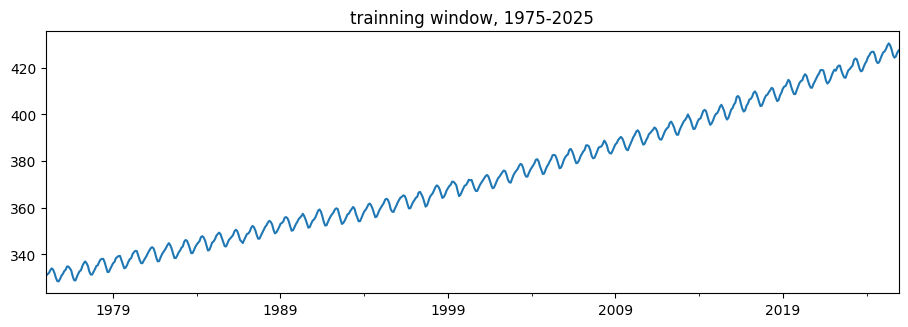

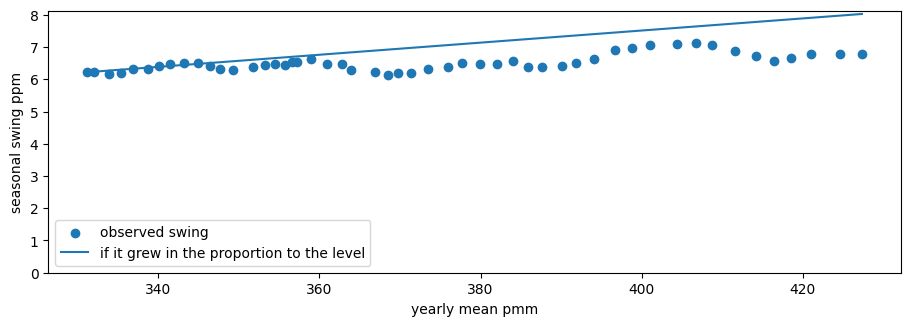

level: 331.1275 -> 427.34916666666663 pmm (+29%)
swing: 6.21999999999997 -> 6.769999999999982 pmm (+9%)


In [15]:
train.plot(title="trainning window, 1975-2025")
plt.show()

seasonal = (raw["average"]-raw["deseasonalized"]).loc["1975":"2025"]
swing = seasonal.groupby(seasonal.index.year).max() - seasonal.groupby(seasonal.index.year).min()
level = train.groupby(train.index.year).mean()
plt.scatter(level, swing, label="observed swing")
plt.plot(level, swing[1975] * level / level[1975], label="if it grew in the proportion to the level")
plt.ylim(0, None)
plt.xlabel("yearly mean pmm")
plt.ylabel("seasonal swing ppm")
plt.legend()
plt.show()
print(f"level: {level[1975]} -> {level[2025]} pmm ({level[2025] / level[1975] - 1:+.0%})")
print(f"swing: {swing[1975]} -> {swing[2025]} pmm ({swing[2025] / swing[1975] - 1:+.0%})")

ADF, raw series (constant + trend)_ p = 0.995


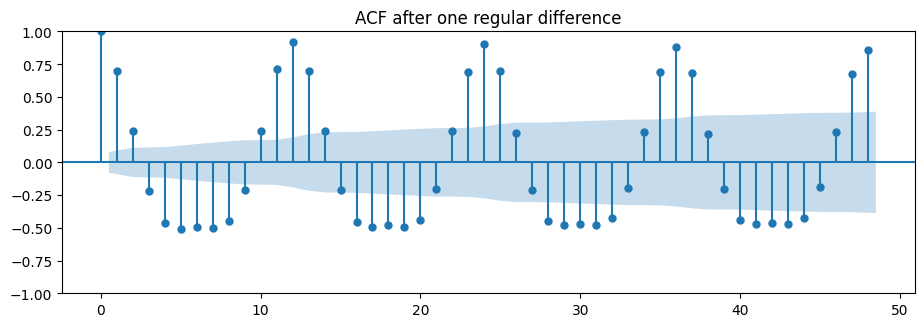

ACF at lags 12, 24, 36, 48 [0.92 0.9  0.88 0.86]


In [16]:
print("ADF, raw series (constant + trend)_ p =", round(adfuller(train, regression="ct")[1],3))
plot_acf(train.diff().dropna(), lags = 48, title="ACF after one regular difference")
plt.show()
print("ACF at lags 12, 24, 36, 48", acf(train.diff().dropna(), nlags=48)[[12,24,36,48]].round(2))

ADF, z: p= 1.928025e-17


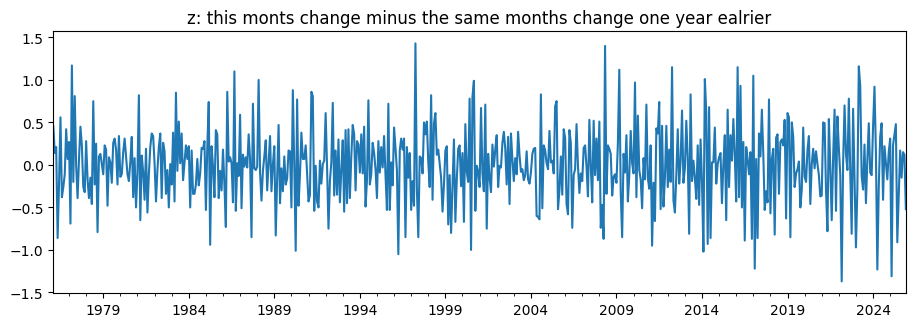

In [19]:
z = train.diff().diff(12).dropna()
print("ADF, z: p=", f"{adfuller(z)[1]:1e}")
z.plot(title="z: this monts change minus the same months change one year ealrier")
plt.show()

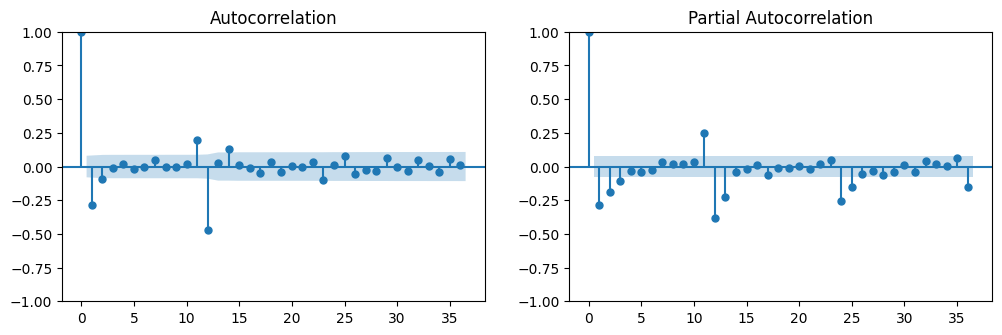

,0
1,-0.28
2,-0.09
3,-0.01
11,0.20
12,-0.47
13,0.03
14,0.13
24,0.01
36,0.01


In [20]:
fig, ax = plt.subplots(1,2,figsize=(12,3.5))
plot_acf(z, lags=36, ax=ax[0])
plot_pacf(z, lags=36, ax=ax[1], method="ywm")
plt.show()

acf_z = acf(z, nlags=36)
lags = [1,2,3,11,12,13,14,24,36]
pd.Series(acf_z[lags], index=lags).round(2)

In [25]:
import statsmodels.api as sm

fit = sm.tsa.statespace.SARIMAX(train, order=(0,1,1), seasonal_order=(0,1,1,12)).fit(disp=False)
print(fit.summary().tables[1])

theta, Theta = fit.params["ma.L1"], fit.params["ma.S.L12"]
print("ACG the model predicts at lags 11 and 13:", round(theta * Theta / ((1 + theta**2)* (1 + Theta**2)),2))
print("ACF in the data at lags 11 and 13:", round(acf_z[11],2),round(acf_z[13],2))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4104      0.035    -11.757      0.000      -0.479      -0.342
ma.S.L12      -0.8848      0.022    -39.709      0.000      -0.928      -0.841
sigma2         0.0991      0.005     19.560      0.000       0.089       0.109
ACG the model predicts at lags 11 and 13: 0.17
ACF in the data at lags 11 and 13: 0.2 0.03


In [31]:
candidates = {
    "airline (0,1,1)(0,1,1)": ((0,1,1), (0,1,1,12)),
    "+ AR(1)": ((1,1,1), (0,1,1,12)),
    "+ MA(2), q = 2": ((0,1,2), (0,1,1,12)),
    "+ seasonal AR(1)": ((0,1,1), (1,1,1,12)),
    "AR version (1,1,0)(1,1,0)": ((1,1,0), (1,1,0,12)),
}

rows = []
for name, (orders, seasonal_order) in candidates.items():
    f = sm.tsa.statespace.SARIMAX(train, order=orders, seasonal_order=seasonal_order, simple_differencing=True).fit(disp=False, maxiter=50)
    k = len(f.params) - 1
    lb_p = acorr_ljungbox(f.resid.iloc[13:], lags=[24], model_df=k)["lb_pvalue"].iloc[0]
    rows.append({"model": name, "AIC": round(f.aic, 1), "BIC": round(f.bic,1), "Ljung_box p": round(lb_p,3)})
pd.DataFrame(rows).sort_values("BIC")

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,model,AIC,BIC,Ljung_box p
0,"airline (0,1,1)(0,1,1)",339.6,352.8,0.707
1,+ AR(1),338.1,355.7,0.798
2,"+ MA(2), q = 2",338.1,355.7,0.798
3,+ seasonal AR(1),341.4,358.9,0.633
4,"AR version (1,1,0)(1,1,0)",516.8,529.9,0.000
